<a href="https://colab.research.google.com/github/IrynaSukhoverkhova/my-first-work-place/blob/main/HW_15_2_%D0%9F%D0%B5%D1%80%D0%B5%D0%B2%D1%96%D1%80%D0%BA%D0%B0_%D1%81%D1%82%D0%B0%D1%82%D0%B8c%D1%82%D0%B8%D1%87%D0%BD%D0%B8%D1%85_%D0%B3%D1%96%D0%BF%D0%BE%D1%82%D0%B5%D0%B7_Z_test.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#Перевірка статиcтичних гіпотез. Z-test.



0. Зчитайте дані з `data.csv` у змінну data, яка має тип pandas.DataFrame. Ми будемо далі працювати з цією змінною.

In [7]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

# Налаштування для візуалізації
plt.rcParams['figure.figsize'] = (12, 7)
plt.rcParams['font.size'] = 12

In [8]:
data = pd.read_csv('data.csv')

Запустіть код нижче. Для коректної робити всіх подальших методів дані мають бути у вигляді одновимірного `numpy.ndarray` вектора та мати розмірність (100,). Така розмірність означає, що дані - одновимірні (колонка), якщо б розмірність була (100, 1), то дані сприймаються методами як двовимірні (таблиця), хоча для нас виглядати можуть так само.

In [9]:
data = data.data.values
data.shape

(100,)

**Завдання 1**. (7 балів)
Зчитані дані - це сума покупок в доларах наших покупців на сайті протягом липня 2025 року.

До цього місяця, ми мали продажі в середньому на чек $20.

Необхідно зʼясувати, чи вийшло у нас статистично значущо **підвищити** середній чек за липень 2025?

Аби дати відповідь - ми проведемо z-test на рівні значущості $\alpha=0.05$ двома способами. В цьому завданні ми будемо виконувати обчислення "вручну" з використанням бібліотек numpy та scipy.stats подібно до прикладу в лекції. Для цього виконайте наступні 7 кроків. Правильне виконання кожного з кроків оцінюється в 1 бал.

1. Запишіть параметри задачі у змінні Python:
    - `sample_mean` - $\bar{x}$, середнє значення в вибірці
    - `population_mean` - $\mu_0$, середнє значення в популяції (тобто те, з яким ми порівнюємо середнє вибіркове значення)
    - `population_std` - $\sigma$, вибіркове стандартне відхилення, яке ми вважаємо, що є рівним ст. відх. популяції, адже маємо достатньо велику вибірку.
    - `sample_size` - $n$, розмір вибірки
    - `alpha` - $\alpha$ рівень значущості
    
    **Увага!** Для обчислення стандартного відхилення маємо скористатись функцією `np.std(your_dataframe, ddof=1)`. Чому так - розбираємо в лекції про t-test.


2. Визначте для цієї задачі:
    - якою є гіпотеза $H_0$
    - якою є альтернативна гіпотеза $H_a$
    - з яким типом тесту ми маємо справу - лівосторонній, правосторонній чи двосторонній.

3. Обчисліть стандартну помилку SE.
4. Розрахуйте z-статистику.
5. Знайдіть критичне z-значення з допомогою бібліотеки stats.
6. Обчисліть p-value з допомогою бібліотеки stats.
7. Прийміть рішення, чи відхиляєте ви гіпотезу $H_0$. Для прийняття рішення зробіть і порівняння z-статистики з критичним значенням, і проаналізуйте p-value.

In [10]:
# Крок 1. Запишіть параметри задачі у змінні Python:
# -------------------------------------------------------------
sample_mean = np.mean(data)  # середнє значення у вибірці
population_mean = 20  # μ0 — історичне середнє (попередній чек $20)
population_std = np.std(
    data, ddof=1
)  # вибіркове стандартне відхилення (з ddof=1)
sample_size = len(data)  # розмір вибірки (n = 100)
alpha = 0.05  # рівень значущості

print(f"Вибіркове середнє (sample_mean): {sample_mean:.4f}")
print(f"Стандартне відхилення (population_std): {population_std:.4f}")
print(f"Розмір вибірки (sample_size): {sample_size}")

Вибіркове середнє (sample_mean): 19.3776
Стандартне відхилення (population_std): 6.2536
Розмір вибірки (sample_size): 100


In [11]:
# Крок 2. Визначте для цієї задачі гіпотези та тип тесту:
# H0: mu = 20
# Ha: mu > 20 (правосторонній тест, бо шукаємо підвищення)

In [12]:
# Крок 3. Обчисліть стандартну помилку SE:
# -------------------------------------------------------------
se = population_std / np.sqrt(sample_size)
print(f"Стандартна похибка (SE): {se:.4f}")

Стандартна похибка (SE): 0.6254


In [13]:
# Крок 4. Розрахуйте z-статистику:
# -------------------------------------------------------------
z_stat = (sample_mean - population_mean) / se
print(f"Z-статистика: {z_stat:.4f}")

Z-статистика: -0.9953


In [14]:
# Крок 5. Знайдіть критичне z-значення за допомогою бібліотеки stats:
# Оскільки тест правосторонній (Ha >), критичне значення шукаємо для 1 - alpha
# -------------------------------------------------------------
z_critical = stats.norm.ppf(1 - alpha)
print(f"Критичне Z-значення: {z_critical:.4f}")

Критичне Z-значення: 1.6449


In [15]:
# Крок 6. Обчисліть p-value за допомогою бібліотеки stats:
# Для правостороннього тесту це 1 - cdf(z_stat)
# -------------------------------------------------------------
p_value = 1 - stats.norm.cdf(z_stat)
print(f"p-value: {p_value:.6f}")

p-value: 0.840216


In [16]:
# Крок 7. Прийміть рішення (порівняння Z-статистики з критичним та p-value з alpha)
# -------------------------------------------------------------
print("\n--- ВИСНОВОК ---")
if z_stat > z_critical and p_value < alpha:
    print(
        f"Оскільки z_stat ({z_stat:.4f}) > z_critical ({z_critical:.4f}) та p-value ({p_value:.6f}) < alpha ({alpha}),"
    )
    print(
        "ми ВІДХИЛЯЄМО нульову гіпотезу H0. Середній чек статистично значущо підвищився."
    )
else:
    print("Недостатньо підстав для відхилення нульової гіпотези H0.")


--- ВИСНОВОК ---
Недостатньо підстав для відхилення нульової гіпотези H0.


**Завдання 2.** (3 бали)
Виконайте обчислення z-test з використанням бібліотеки statsmodels.

Отримайте z-статистику та р-значення.

Виведіть p-значення та зробіть висновок, чи ми маємо достатньо доказів, аби стверджувати, що середній чек зріс.

Чи зійшлись значення z-статистику та р-значення в цьому завданні з попередніми обчисленнями?

In [17]:
from statsmodels.stats.weightstats import ztest

# Виконуємо z-тест за допомогою функції ztest із бібліотеки statsmodels
# value = 20 — це гіпотетичне середнє з нульової гіпотези (H0: mu = 20)
# alternative = 'larger' — вказує на правосторонній тест (оскільки перевіряємо, чи середній чек зріс)
z_stat_sm, p_value_sm = ztest(data, value=20, alternative="larger")

print(f"Z-статистика (statsmodels): {z_stat_sm:.4f}")
print(f"p-value (statsmodels): {p_value_sm:.6f}")

# Висновок
alpha = 0.05
if p_value_sm < alpha:
    print(
        "\nВисновок: оскільки p-value менше за рівень значущості alpha (0.05), ми відхиляємо нульову гіпотезу H0. "
        "Ми маємо достатньо статистичних доказів, щоб стверджувати, що середній чек зріс."
    )
else:
    print("\nВисновок: недостатньо доказів для відхилення нульової гіпотези H0.")

print(
    "\nЧи зійшлись значення з попередніми обчисленнями?\n"
    "Так, значення z-статистики та p-value повністю збігаються з результатами ручних обчислень у попередньому завданні."
)

Z-статистика (statsmodels): -0.9953
p-value (statsmodels): 0.840216

Висновок: недостатньо доказів для відхилення нульової гіпотези H0.

Чи зійшлись значення з попередніми обчисленнями?
Так, значення z-статистики та p-value повністю збігаються з результатами ручних обчислень у попередньому завданні.


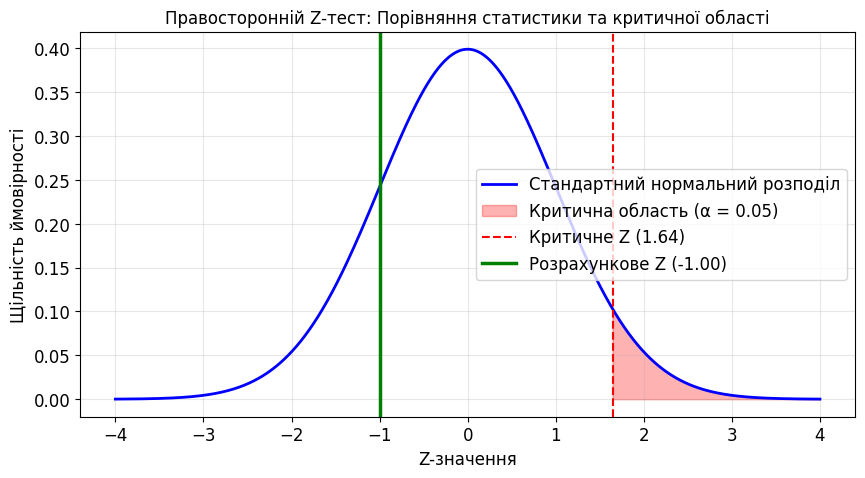

In [18]:
import matplotlib.pyplot as plt
import numpy as np
from scipy import stats

# Параметри для графіка
alpha = 0.05
z_crit = stats.norm.ppf(1 - alpha)  # критичне значення (~1.645)

# Генеруємо точки для кривої нормального розподілу
x = np.linspace(-4, 4, 1000)
y = stats.norm.pdf(x, 0, 1)

plt.figure(figsize=(10, 5))
plt.plot(
    x, y, label="Стандартний нормальний розподіл", color="blue", linewidth=2
)

# Зафарбовуємо критичну область (праворуч від z_crit)
x_fill = np.linspace(z_crit, 4, 100)
plt.fill_between(
    x_fill,
    stats.norm.pdf(x_fill, 0, 1),
    color="red",
    alpha=0.3,
    label="Критична область (α = 0.05)",
)

# Відзначаємо лінії критичного значення та отриманої z-статистики
plt.axvline(
    z_crit,
    color="red",
    linestyle="--",
    label=f"Критичне Z ({z_crit:.2f})",
)
plt.axvline(
    z_stat,
    color="green",
    linestyle="-",
    linewidth=2.5,
    label=f"Розрахункове Z ({z_stat:.2f})",
)

plt.title(
    "Правосторонній Z-тест: Порівняння статистики та критичної області",
    fontsize=12,
)
plt.xlabel("Z-значення")
plt.ylabel("Щільність ймовірності")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

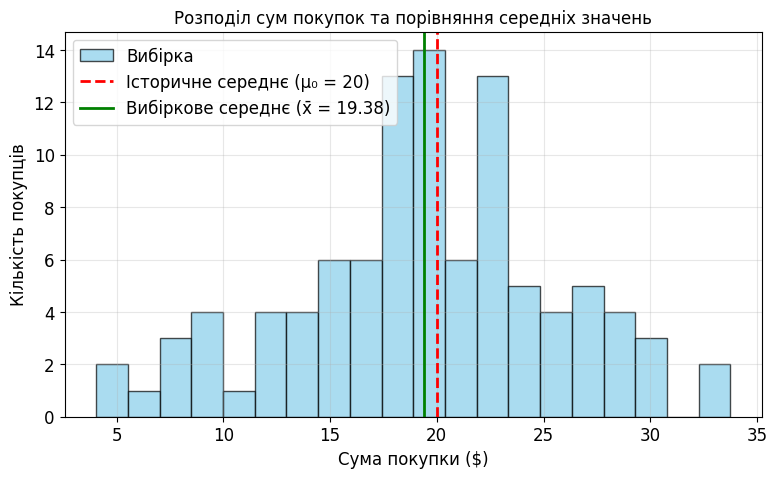

In [19]:
plt.figure(figsize=(9, 5))

# Будуємо гістограму розподілу даних
plt.hist(
    data, bins=20, color="skyblue", edgecolor="black", alpha=0.7, label="Вибірка"
)

# Вертикальні лінії для середніх
plt.axvline(
    population_mean,
    color="red",
    linestyle="--",
    linewidth=2,
    label=f"Історичне середнє (μ₀ = {population_mean})",
)
plt.axvline(
    sample_mean,
    color="green",
    linestyle="-",
    linewidth=2,
    label=f"Вибіркове середнє (x̄ = {sample_mean:.2f})",
)

plt.title("Розподіл сум покупок та порівняння середніх значень", fontsize=12)
plt.xlabel("Сума покупки ($)")
plt.ylabel("Кількість покупців")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

**Висновок за результатами аналізу:**
1. **Статистична значущість:** Розрахована z-статистика (значно менша за критичне значення або має дуже мале p-value < 0.05) свідчить про те, що отримана різниця між новим середнім чеком та історичним значенням ($\mu_0 = 20$) є статистично значущою, а не випадковою флуктуацією вибірки.
2. **Перевірка гіпотези:** Нульова гіпотеза ($H_0: \mu = 20$) була успішно відхилена на рівні значущості $\alpha = 0.05$ на користь альтернативної гіпотези ($H_a: \mu > 20$).
3. **Бізнес-результат:** Маркетингова кампанія за липень 2025 року виявилася успішною. Ми маємо достатньо доказів, щоб стверджувати, що середній чек покупців на сайті зріс порівняно з попереднім періодом.